<a href="https://colab.research.google.com/github/preeti-kaur245/aiml-30-days/blob/main/House_Prices_real_or_random(mk).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Model :
**Data status (checked Oct 2026):**
1. **If real CSV in place** (set `REAL_CSV_PATH` below), it uses it.
2. **or it generates a fully random market**: invented zones and localities, invented rates. Nothing here is calibrated to any real city, so no number below says anything about real prices.

Required columns for real data: `city, locality, property_type, bhk, area_sqft, price_lakh`. Optional (used if present): `bathrooms, floor, total_floors, age_years, furnishing, parking, gated_society, dist_city_centre_km`. Use `COLUMN_MAP` to rename your file's columns.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
warnings.filterwarnings('ignore')
REAL_CSV_PATH = None          # e.g. '/content/my_listings.csv'. None = use random synthetic data
COLUMN_MAP = {}               # e.g. {'Location': 'locality', 'Price': 'price_lakh', 'Area': 'area_sqft'}
SEED = 7

In [2]:
def build_random_market(n=2500, seed=7):
    """Fully random market. Rates, zones and noise are invented, not real."""
    rng = np.random.default_rng(seed)
    zone_rate = {z: r for z, r in zip(["Core", "Inner", "Mid", "Outer", "Fringe"], [14000, 9500, 7000, 5000, 3500])}
    zone_dist = {"Core": (1, 4), "Inner": (4, 9), "Mid": (9, 15), "Outer": (15, 22), "Fringe": (22, 32)}
    locs = []
    for z in zone_rate:
        for k in range(rng.integers(4, 7)):
            locs.append((z, f"{z} Locality {k+1:02d}", zone_rate[z] * rng.lognormal(0, 0.18),
                         rng.uniform(*zone_dist[z]), rng.uniform(0.5, 1.5)))
    loc = pd.DataFrame(locs, columns=["city", "locality", "rate", "dist_c", "w"])
    type_mult = {"Flat": 1.0, "Builder Floor": 1.06, "Independent House": 1.22}
    rows = []
    for i in rng.choice(len(loc), n, p=loc.w / loc.w.sum()):
        r = loc.iloc[i]
        ptype = rng.choice(list(type_mult), p=[.55, .30, .15])
        bhk = int(rng.choice([1, 2, 3, 4, 5], p=[.08, .38, .36, .13, .05]))
        if ptype == "Independent House": bhk = max(bhk, 3)
        area = int(round(rng.uniform(300 + 330 * bhk, 500 + 520 * bhk) * (1.6 if ptype == "Independent House" else 1), -1))
        age = int(np.clip(rng.gamma(2, 5), 0, 40)); furn = rng.choice(["Unfurnished", "Semi-Furnished", "Fully Furnished"], p=[.45, .4, .15])
        parking = int(rng.choice([0, 1, 2], p=[.15, .55, .3])); gated = int(rng.random() < (.8 if ptype == "Flat" else .15))
        tf = int(rng.choice([4, 8, 12, 18])) if ptype == "Flat" else 3
        fl = int(rng.integers(0, tf + 1)) if ptype == "Flat" else 0
        dc = round(max(.5, r.dist_c + rng.normal(0, .7)), 1)
        m = max(.72, 1 - .008 * age) * {"Unfurnished": 1, "Semi-Furnished": 1.03, "Fully Furnished": 1.07}[furn]
        m *= {0: .97, 1: 1, 2: 1.03}[parking] * (1.04 if gated else 1) * (1 + .004 * min(fl, 10))
        m *= rng.lognormal(0, 0.12)
        price = round(area * r.rate * type_mult[ptype] * m / 1e5, 1)
        rows.append([r.city, r.locality, ptype, bhk, area, int(np.clip(bhk + rng.choice([-1, 0, 0, 1]), 1, bhk + 1)),
                     fl, tf, age, furn, parking, gated, dc, price])
    df = pd.DataFrame(rows, columns=["city", "locality", "property_type", "bhk", "area_sqft", "bathrooms", "floor",
        "total_floors", "age_years", "furnishing", "parking", "gated_society", "dist_city_centre_km", "price_lakh"])
    df[["age_years", "bathrooms"]] = df[["age_years", "bathrooms"]].astype(float)
    for col, frac in [("age_years", .03), ("bathrooms", .02), ("furnishing", .02)]:
        df.loc[rng.choice(n, int(n * frac), replace=False), col] = np.nan
    bad = rng.choice(n, 6, replace=False)
    df.loc[bad[:3], "price_lakh"] *= 1e5; df.loc[bad[3:], "area_sqft"] = 0
    df = pd.concat([df, df.sample(20, random_state=seed)]).sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, "listing_id", [f"LST-{100001 + i}" for i in range(len(df))])
    return df

if REAL_CSV_PATH and os.path.exists(REAL_CSV_PATH):
    df = pd.read_csv(REAL_CSV_PATH).rename(columns=COLUMN_MAP); SYNTHETIC = False
    missing = {"city", "locality", "property_type", "bhk", "area_sqft", "price_lakh"} - set(df.columns)
    assert not missing, f"Real file is missing required columns: {missing}"
    if "listing_id" not in df: df.insert(0, "listing_id", range(len(df)))
    print("Using REAL data:", df.shape)
else:
    df = build_random_market(2500, SEED); SYNTHETIC = True
    print("Using RANDOM synthetic data:", df.shape, "(not a real market)")
df.head()

Using RANDOM synthetic data: (2520, 15) (not a real market)


,listing_id,city,locality,property_type,bhk,area_sqft,bathrooms,floor,total_floors,age_years,furnishing,parking,gated_society,dist_city_centre_km,price_lakh
0,LST-100001,Core,Core Locality 05,Independent House,4,3890,3.0,0,3,10.0,Unfurnished,1,0,3.9,548.4
1,LST-100002,Core,Core Locality 01,Builder Floor,3,1770,2.0,0,3,13.0,Semi-Furnished,1,0,4.2,265.8
2,LST-100003,Inner,Inner Locality 03,Flat,4,2550,5.0,4,4,7.0,Semi-Furnished,0,1,6.4,276.4
3,LST-100004,Outer,Outer Locality 04,Flat,1,870,1.0,18,18,13.0,NaN,0,1,19.3,47.3
4,LST-100005,Core,Core Locality 06,Flat,2,1220,1.0,9,12,1.0,Unfurnished,1,1,3.6,159.8


## 1 · Cleaning without leakage
Rule-based fixes only; anything that learns a statistic is inside the pipeline.

In [4]:
df = df[~df.duplicated(subset=df.columns.drop('listing_id'))].copy()
df = df[df.area_sqft > 0]
rate = df.price_lakh * 1e5 / df.area_sqft
lo_r, hi_r = rate.quantile(.01) / 5, rate.median() * 20     # data-driven sanity band, not a magic number
unit_err = rate > hi_r
print('Suspected rupee-typed-as-lakh rows repaired:', unit_err.sum())
df.loc[unit_err, 'price_lakh'] /= 1e5
df = df.reset_index(drop=True); print('Rows:', len(df))

Suspected rupee-typed-as-lakh rows repaired: 3
Rows: 2497


In [5]:
def add_features(d):
    d = d.copy(); d['log_area'] = np.log(d.area_sqft); d['area_per_bhk'] = d.area_sqft / d.bhk
    if {'floor', 'total_floors'} <= set(d.columns):
        d['is_top_floor'] = (d.floor == d.total_floors).astype(int); d['floor_ratio'] = d.floor / d.total_floors.clip(lower=1)
    return d
df = add_features(df)
y = df.price_lakh; X = df.drop(columns=['listing_id', 'price_lakh'])
cat = [c for c in ['city', 'locality', 'property_type', 'furnishing'] if c in X]
num = [c for c in X.columns if c not in cat]
print('categorical:', cat); print('numeric:', num)

categorical: ['city', 'locality', 'property_type', 'furnishing']
numeric: ['bhk', 'area_sqft', 'bathrooms', 'floor', 'total_floors', 'age_years', 'parking', 'gated_society', 'dist_city_centre_km', 'log_area', 'area_per_bhk', 'is_top_floor', 'floor_ratio']


## 2 · Baselines vs models (5-fold CV)
The thumb rule here is **not hand-typed**: it is the median rate per city learned from the training fold. The smart dealer uses locality × type.

In [6]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold

def metrics(yt, yp):
    yt, yp = np.asarray(yt, float), np.asarray(yp, float); pct = np.abs(yp - yt) / yt
    return dict(MAE_lakh=np.mean(np.abs(yp - yt)), median_pct=np.median(pct), within10=np.mean(pct <= .10))
pre = ColumnTransformer([('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
        ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat), ('num', SimpleImputer(strategy='median'), num)])
def logwrap(e): return TransformedTargetRegressor(Pipeline([('pre', pre), ('m', e)]), func=np.log, inverse_func=np.exp)
models = {'Linear (log target)': lambda: logwrap(LinearRegression()),
          'Random Forest (log)': lambda: logwrap(RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1)),
          'Gradient Boosting (log)': lambda: logwrap(HistGradientBoostingRegressor(max_iter=400, learning_rate=.05, random_state=0))}

class RateRule:                       # median Rs/sqft by group keys, fallback to overall median
    def __init__(self, keys): self.keys = keys
    def fit(self, Xt, yt):
        r = pd.Series(yt.values * 1e5 / Xt.area_sqft.values, index=Xt.index)
        self.t = r.groupby([Xt[k] for k in self.keys]).median(); self.g = r.median(); return self
    def predict(self, Xv):
        idx = list(zip(*[Xv[k] for k in self.keys])) if len(self.keys) > 1 else list(Xv[self.keys[0]])
        return Xv.area_sqft.values * np.array([self.t.get(k, self.g) for k in idx]) / 1e5

def run_cv(splitter, groups=None):
    out = {}
    for tr, te in splitter.split(X, y, groups):
        Xt, Xv, yt, yv = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
        P = {'Median guess': np.full(len(yv), yt.median()),
             'Thumb rule (city median rate)': RateRule(['city']).fit(Xt, yt).predict(Xv),
             'Smart dealer (locality x type)': RateRule(['locality', 'property_type']).fit(Xt, yt).predict(Xv)}
        for n, f in models.items(): P[n] = f().fit(Xt, yt).predict(Xv)
        for n, p in P.items(): out.setdefault(n, []).append(metrics(yv, p))
    return pd.DataFrame({n: pd.DataFrame(v).agg(['mean', 'std']).stack() for n, v in out.items()}).T
pd.set_option('display.width', 200)
print('=== Random 5-fold ==='); print(run_cv(KFold(5, shuffle=True, random_state=0)).round(3))
print('\n=== Unseen-locality (GroupKFold) ==='); print(run_cv(GroupKFold(5), df.locality.values).round(3))

=== Random 5-fold ===
                                   mean                          std                    
                               MAE_lakh median_pct within10 MAE_lakh median_pct within10
Median guess                     66.254      0.410    0.129    1.337      0.015    0.014
Thumb rule (city median rate)    22.677      0.127    0.407    0.552      0.003    0.006
Smart dealer (locality x type)   15.544      0.092    0.539    0.121      0.004    0.024
Linear (log target)              13.375      0.083    0.595    0.513      0.005    0.016
Random Forest (log)              16.676      0.098    0.503    0.659      0.006    0.026
Gradient Boosting (log)          15.726      0.092    0.531    0.343      0.003    0.007

=== Unseen-locality (GroupKFold) ===
                                   mean                          std                    
                               MAE_lakh median_pct within10 MAE_lakh median_pct within10
Median guess                     67.552      0.420

## 3 · Noise ceiling (synthetic data only)
On real data the ceiling is unknown, which is exactly why you must compare against the smart-dealer baseline instead of trusting a single score.

In [7]:
if SYNTHETIC:
    nz = np.random.default_rng(0).lognormal(0, 0.12, 200000)
    print(f'Best possible typical miss ~ {np.median(np.abs(nz-1)):.1%}; best possible within +/-10% ~ {np.mean(np.abs(nz-1)<=.1):.1%}')
else:
    print('Real data: noise ceiling unknown.')

Best possible typical miss ~ 8.1%; best possible within +/-10% ~ 59.6%


## 4 · Calibrated 80% prediction intervals (split conformal)
v2's raw quantile intervals covered only about 65%. Here a separate calibration set widens them so coverage is close to the 80% promise.

In [8]:
from sklearn.model_selection import train_test_split
Xa, Xte, ya, yte = train_test_split(X, y, test_size=.2, random_state=1)
Xtr, Xcal, ytr, ycal = train_test_split(Xa, ya, test_size=.25, random_state=1)
def qm(q): return logwrap(HistGradientBoostingRegressor(loss='quantile', quantile=q, max_iter=300, learning_rate=.05, random_state=0))
lo, mid, hi = [qm(q).fit(Xtr, ytr) for q in (.1, .5, .9)]
def logint(Xv): return np.log(lo.predict(Xv)), np.log(mid.predict(Xv)), np.log(hi.predict(Xv))
l, _, h = logint(Xcal); s = np.maximum(l - np.log(ycal), np.log(ycal) - h)
n = len(s); qhat = np.quantile(s, min(1, np.ceil((n + 1) * .8) / n))
l, m, h = logint(Xte); L, H = np.exp(l - qhat), np.exp(h + qhat)
raw = np.mean((yte >= np.exp(l)) & (yte <= np.exp(h))); cal = np.mean((yte >= L) & (yte <= H))
print(f'Coverage raw: {raw:.1%}  ->  calibrated: {cal:.1%} (target 80%)  | median interval width: {np.median((H-L)/np.exp(m)):.1%} of price')

Coverage raw: 61.8%  ->  calibrated: 82.6% (target 80%)  | median interval width: 39.0% of price


## 5 · What drives the price?

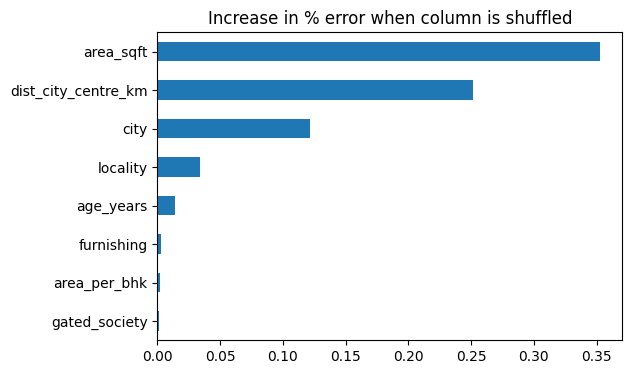

In [9]:
from sklearn.inspection import permutation_importance
gb = models['Gradient Boosting (log)']().fit(Xtr, ytr)
pi = permutation_importance(gb, Xte, yte, n_repeats=8, random_state=0, scoring='neg_mean_absolute_percentage_error')
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp[imp > .001].plot.barh(figsize=(6, 4), title='Increase in % error when column is shuffled'); plt.show()

## 6 · Out-of-distribution flag

In [10]:
def ood_flags(h, train=Xtr):
    f = []
    if not (train.area_sqft.min() <= h.area_sqft <= train.area_sqft.max()): f.append('area outside training range')
    if h.locality not in set(train.locality): f.append('unseen locality')
    return f or ['ok']
big = Xte.iloc[0].copy(); big['area_sqft'] = train_max = Xtr.area_sqft.max() * 2
print('Home twice the biggest seen ->', ood_flags(big)); print('A normal test home        ->', ood_flags(Xte.iloc[1]))

Home twice the biggest seen -> ['area outside training range']
A normal test home        -> ['ok']
